# FinMark Milestone 1: Preprocessing and Exploratory Data Analysis

## Business and Machine Learning Context

FinMark is examining customer demographics, transaction behavior, and social-media interactions to better understand its customers and prepare reliable features for data-driven decision-making. The analysis supports FinMark analysts, data scientists, marketing teams, and business decision-makers who may use the findings for customer segmentation, feature selection, campaign planning, and future predictive modeling.

The three MFML project datasets have complementary analytical roles:
- **Customer demographics** describes customer attributes such as age, gender, location, income level, and signup date.
- **Customer transactions** records purchase dates, amounts, product categories, and payment methods.
- **Social-media interactions** records platform activity, interaction type, date, and sentiment.

`CustomerID` is the relationship key connecting the datasets. `TransactionID` and `InteractionID` identify individual business events and are audited for conflicts before deduplication. Identifiers are used for joins and validation, not as direct predictive features.

## Purpose and Scope

This notebook loads the three contaminated source files supplied for the FinMark MFML project, verifies their structure and quality, documents preprocessing decisions, exports finalized cleaned datasets, and performs EDA. Preprocessing is necessary because unresolved duplicates, missing values, invalid ages, ambiguous transaction amounts, inconsistent date formats, and categorical contamination could bias descriptive findings and future models. The official project source and access link should also be cited in the submitted report or reference section supplied by the course.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

In [7]:
segments = pd.read_csv("customer_demographics_contaminated.csv")
transactions = pd.read_csv("customer_transactions_contaminated.csv")
social = pd.read_csv("social_media_interactions_contaminated.csv")

In [8]:
print("Segments shape:", segments.shape)
print(segments.head())

print("\nTransactions shape:", transactions.shape)
print(transactions.head())

print("\nSocial shape:", social.shape)
print(social.head())

Segments shape: (3200, 6)
                             CustomerID   Age  Gender           Location  \
0  9207fa75-5758-48d1-94ad-19c041e0520f  51.0  Female         Jensenberg   
1  5fb09cd8-a473-46f7-80bd-6e49cf509078   NaN  Female       Castilloport   
2  c139496e-cc89-498a-bd90-1fb4627b6cff  37.0    Male  Lake Jennifertown   
3  50118139-7264-428f-81cc-a25fddc5d6dd  44.0    Male          Port Carl   
4  7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4  50.0  Female          Jessebury   

  IncomeLevel  SignupDate  
0         Low  2022-11-17  
1        High  2020-07-21  
2         NaN  2021-01-01  
3      Medium  2024-06-10  
4        High  2023-08-24  

Transactions shape: (3200, 6)
                             CustomerID                         TransactionID  \
0  60567026-f719-4cd6-849e-137e86d8938f  5ff75116-0a50-4d04-80fb-31e5ccbb0769   
1  4090ba85-b111-4f75-a792-c777965f5255  2c39b9fe-ff57-4d39-9321-9f5cdf187aa1   
2  9223891b-73ff-4d5c-b8ae-13ece82ee28b  f79588dd-3db9-4ffa-97f8-7de0e64259

In [9]:
segments.info()
transactions.info()
social.info()

<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   CustomerID   3200 non-null   str  
 1   Age          2909 non-null   str  
 2   Gender       3200 non-null   str  
 3   Location     3200 non-null   str  
 4   IncomeLevel  2897 non-null   str  
 5   SignupDate   3200 non-null   str  
dtypes: str(6)
memory usage: 150.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   CustomerID       3200 non-null   str  
 1   TransactionID    3200 non-null   str  
 2   TransactionDate  3200 non-null   str  
 3   Amount           2896 non-null   str  
 4   ProductCategory  2901 non-null   str  
 5   PaymentMethod    3200 non-null   str  
dtypes: str(6)
memory usage: 150.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199

In [10]:
print("Segments duplicate rows:", segments.duplicated().sum())
print("Transactions duplicate rows:", transactions.duplicated().sum())
print("Social duplicate rows:", social.duplicated().sum())

print("\nSegments duplicate CustomerID:", segments['CustomerID'].duplicated().sum())
print("Transactions duplicate TransactionID:", transactions['TransactionID'].duplicated().sum())
print("Social duplicate InteractionID:", social['InteractionID'].duplicated().sum())

print("\nSegments missing:\n", segments.isnull().sum())
print("\nTransactions missing:\n", transactions.isnull().sum())
print("\nSocial missing:\n", social.isnull().sum())

Segments duplicate rows: 177
Transactions duplicate rows: 185
Social duplicate rows: 180

Segments duplicate CustomerID: 200
Transactions duplicate TransactionID: 200
Social duplicate InteractionID: 200

Segments missing:
 CustomerID       0
Age            291
Gender           0
Location         0
IncomeLevel    303
SignupDate       0
dtype: int64

Transactions missing:
 CustomerID           0
TransactionID        0
TransactionDate      0
Amount             304
ProductCategory    299
PaymentMethod        0
dtype: int64

Social missing:
 CustomerID           0
InteractionID        0
InteractionDate      0
Platform           311
InteractionType      0
Sentiment          329
dtype: int64


In [11]:
# dtypes alone don't reveal contamination hiding inside object/string columns, so inspect values directly
age_numeric = pd.to_numeric(segments['Age'], errors='coerce')
print("Age = 'Unknown':", (segments['Age'] == 'Unknown').sum())
print("Age out-of-range (<=0 or >100):", ((age_numeric <= 0) | (age_numeric > 100)).sum())
print("IncomeLevel categories:", segments['IncomeLevel'].unique())

amount_numeric = pd.to_numeric(transactions['Amount'], errors='coerce')
print("\nAmount non-numeric values:", transactions.loc[amount_numeric.isnull() & transactions['Amount'].notnull(), 'Amount'].unique())
print("Amount negative values:", (amount_numeric < 0).sum())
print("ProductCategory categories:", transactions['ProductCategory'].unique())

print("\nPlatform categories:", social['Platform'].unique())
print("Sentiment categories:", social['Sentiment'].unique())

# Dates fail to parse with a single format when the column mixes YYYY-MM-DD and DD/MM/YYYY
print("\nUnparseable TransactionDate (ISO-only parse):", pd.to_datetime(transactions['TransactionDate'], format='%Y-%m-%d', errors='coerce').isnull().sum())
print("Unparseable InteractionDate (ISO-only parse):", pd.to_datetime(social['InteractionDate'], format='%Y-%m-%d', errors='coerce').isnull().sum())
print("Unparseable SignupDate (ISO-only parse):", pd.to_datetime(segments['SignupDate'], format='%Y-%m-%d', errors='coerce').isnull().sum())

Age = 'Unknown': 34
Age out-of-range (<=0 or >100): 63
IncomeLevel categories: <StringArray>
['Low', 'High', nan, 'Medium']
Length: 4, dtype: str

Amount non-numeric values: <StringArray>
['Free']
Length: 1, dtype: str
Amount negative values: 40
ProductCategory categories: <StringArray>
[       'Clothing', 'Health & Beauty',      'Automotive',   'Home & Garden',
               nan,     'Electronics']
Length: 6, dtype: str

Platform categories: <StringArray>
[nan, 'Twitter', 'Instagram', 'Facebook']
Length: 4, dtype: str
Sentiment categories: <StringArray>
[nan, 'Neutral', 'Positive', 'Negative', 'Very Negative', 'Very Positive']
Length: 6, dtype: str

Unparseable TransactionDate (ISO-only parse): 98
Unparseable InteractionDate (ISO-only parse): 100
Unparseable SignupDate (ISO-only parse): 98


In [12]:
# Audit non-identical records that share a business ID before deciding which record to retain
def audit_business_key_conflicts(df, key, dataset_name, original_row_count=3000):
    source = df.reset_index(names="SourceRow")
    data_columns = df.columns.tolist()
    unique_records = source.drop_duplicates(subset=data_columns)
    conflicts = unique_records[unique_records.duplicated(key, keep=False)].copy()
    
    differing_fields = {}
    for business_id, group in conflicts.groupby(key):
        differing_fields[business_id] = ", ".join(
            column for column in data_columns
            if column != key and group[column].fillna("<MISSING>").nunique() > 1
        )
    conflicts["DifferingFields"] = conflicts[key].map(differing_fields)
    
    source_positions = conflicts.groupby(key)["SourceRow"].agg(list)
    original_appended_pairs = source_positions.apply(
        lambda rows: len(rows) == 2 and min(rows) < original_row_count <= max(rows)
    )
    summary = {
        "Dataset": dataset_name,
        "Exact duplicate rows": int(df.duplicated().sum()),
        "Conflicting IDs": int(source_positions.size),
        "Original/appended pairs": int(original_appended_pairs.sum()),
        "Other conflict patterns": int((~original_appended_pairs).sum()),
    }
    return conflicts.sort_values([key, "SourceRow"]), summary

segment_conflicts, segment_audit = audit_business_key_conflicts(
    segments, "CustomerID", "Customer Demographics"
)
transaction_conflicts, transaction_audit = audit_business_key_conflicts(
    transactions, "TransactionID", "Transactions"
)
social_conflicts, social_audit = audit_business_key_conflicts(
    social, "InteractionID", "Social Interactions"
)

conflict_summary = pd.DataFrame([segment_audit, transaction_audit, social_audit])
display(conflict_summary)
display(transaction_conflicts.head(10))

,Dataset,Exact duplicate rows,Conflicting IDs,Original/appended pairs,Other conflict patterns
0,Customer Demographics,177,23,23,0
1,Transactions,185,15,15,0
2,Social Interactions,180,20,20,0


,SourceRow,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod,DifferingFields
2118,2118,778da54b-8f96-4609-a21b-bba3d7f071ea,022cfd97-a8e8-4e50-8700-2720d52bfd75,2022-08-23,586.87,Health & Beauty,PayPal,Amount
3005,3005,778da54b-8f96-4609-a21b-bba3d7f071ea,022cfd97-a8e8-4e50-8700-2720d52bfd75,2022-08-23,Free,Health & Beauty,PayPal,Amount
413,413,6a84f1a7-f636-4300-bd8d-c7f888460829,185ee140-348a-4461-bd40-07a7e8535815,2023-10-09,953.86,Health & Beauty,PayPal,Amount
3174,3174,6a84f1a7-f636-4300-bd8d-c7f888460829,185ee140-348a-4461-bd40-07a7e8535815,2023-10-09,0,Health & Beauty,PayPal,Amount
431,431,b94b3531-591d-445c-b282-dcacb0baca5b,27fb25aa-f148-423f-967c-4d1764e26b29,30/07/2022,506.96,Automotive,Credit Card,"TransactionDate, Amount"
3038,3038,b94b3531-591d-445c-b282-dcacb0baca5b,27fb25aa-f148-423f-967c-4d1764e26b29,2024-04-18,-100,Automotive,Credit Card,"TransactionDate, Amount"
2081,2081,e7cf6999-b4ec-4ce4-bb09-bfd18d61d933,2e0b66a9-af5d-4cf9-bb60-55ab2932edee,2023-05-10,504.42,Electronics,Bank Transfer,Amount
3073,3073,e7cf6999-b4ec-4ce4-bb09-bfd18d61d933,2e0b66a9-af5d-4cf9-bb60-55ab2932edee,2023-05-10,-100,Electronics,Bank Transfer,Amount
220,220,a9af986b-d677-421a-81df-3d289ce9e38f,5f93f1dc-0363-4e69-979b-f5d58fd42658,2023-09-30,125.77,NaN,Bank Transfer,Amount
3050,3050,a9af986b-d677-421a-81df-3d289ce9e38f,5f93f1dc-0363-4e69-979b-f5d58fd42658,2023-09-30,-100,NaN,Bank Transfer,Amount


In [13]:
# Helper: SignupDate/TransactionDate/InteractionDate mix YYYY-MM-DD and DD/MM/YYYY strings
def parse_mixed_dates(series):
    iso = pd.to_datetime(series, format='%Y-%m-%d', errors='coerce')
    dmy = pd.to_datetime(series, format='%d/%m/%Y', errors='coerce')
    return iso.fillna(dmy)

In [14]:
# --- Clean Segments: remove exact/appended duplicates, fix Age, handle categories, parse dates ---
# The audit proves every ID conflict is an original row (0-2999) plus a modified appended copy (3000-3199).
segments = segments.drop_duplicates()
segments = segments.drop_duplicates(subset='CustomerID', keep='first')

segments['Age'] = segments['Age'].replace('Unknown', np.nan)
segments['Age'] = pd.to_numeric(segments['Age'], errors='coerce')
segments.loc[(segments['Age'] <= 0) | (segments['Age'] > 100), 'Age'] = np.nan
segments['Age'] = segments['Age'].fillna(segments['Age'].median())

segments['Gender'] = segments['Gender'].str.strip()
# Missing IncomeLevel is ~10% of rows; keep the rows and flag as its own category instead of dropping them
segments['IncomeLevel'] = segments['IncomeLevel'].fillna('Unknown')

segments['SignupDate'] = parse_mixed_dates(segments['SignupDate'])
segments['CustomerID'] = segments['CustomerID'].astype(str).str.strip()

In [15]:
# --- Clean Transactions: remove exact/appended duplicates, preserve ambiguous amount semantics, parse dates ---
transactions = transactions.drop_duplicates()
transactions = transactions.drop_duplicates(subset='TransactionID', keep='first')

transactions['AmountRaw'] = transactions['Amount'].astype('string').str.strip()
transactions['IsFreeLabel'] = transactions['AmountRaw'].str.casefold().eq('free').fillna(False).astype(bool)
transactions['WasAmountImputed'] = transactions['AmountRaw'].isna()
transactions['Amount'] = pd.to_numeric(transactions['AmountRaw'], errors='coerce')
amount_median = transactions['Amount'].median()
transactions.loc[transactions['WasAmountImputed'], 'Amount'] = amount_median
transactions['IsNegativeAmount'] = transactions['Amount'].lt(0).fillna(False).astype(bool)
transactions['AmountReviewStatus'] = np.select(
    [transactions['IsFreeLabel'], transactions['WasAmountImputed'], transactions['IsNegativeAmount']],
    ['Business meaning of "Free" requires validation', 'Missing source amount - median imputed', 'Possible refund/reversal/adjustment'],
    default='Observed numeric amount',
)
# Preserve signed negatives and unresolved Free labels; only genuinely missing source amounts are imputed.

transactions['ProductCategory'] = transactions['ProductCategory'].fillna('Unknown')
transactions['PaymentMethod'] = transactions['PaymentMethod'].str.strip()

transactions['TransactionDate'] = parse_mixed_dates(transactions['TransactionDate'])
transactions['CustomerID'] = transactions['CustomerID'].astype(str).str.strip()
transactions['TransactionID'] = transactions['TransactionID'].astype(str).str.strip()

In [16]:
# --- Clean Social: remove exact/appended duplicates, handle missing categories, parse dates ---
social = social.drop_duplicates()
social = social.drop_duplicates(subset='InteractionID', keep='first')

social['Platform'] = social['Platform'].fillna('Unknown')
social['Sentiment'] = social['Sentiment'].fillna('Unknown')
social['InteractionType'] = social['InteractionType'].str.strip()

social['InteractionDate'] = parse_mixed_dates(social['InteractionDate'])
social['CustomerID'] = social['CustomerID'].astype(str).str.strip()
social['InteractionID'] = social['InteractionID'].astype(str).str.strip()

In [17]:
# --- Post-cleaning verification: confirm dedupe, missing-value, dtype, and amount-review outcomes ---
print("Duplicate rows -> Segments:", segments.duplicated().sum(), "Transactions:", transactions.duplicated().sum(), "Social:", social.duplicated().sum())
print("Duplicate IDs -> CustomerID:", segments['CustomerID'].duplicated().sum(),
      "TransactionID:", transactions['TransactionID'].duplicated().sum(),
      "InteractionID:", social['InteractionID'].duplicated().sum())

print("\nSegments missing:\n", segments.isnull().sum())
print("\nTransactions missing (Free labels remain unresolved by design):\n", transactions.isnull().sum())
print("\nSocial missing:\n", social.isnull().sum())
print("\nTransaction amount review status:\n", transactions['AmountReviewStatus'].value_counts())

segments.info()
transactions.info()
social.info()

Duplicate rows -> Segments: 0 Transactions: 0 Social: 0
Duplicate IDs -> CustomerID: 0 TransactionID: 0 InteractionID: 0

Segments missing:
 CustomerID     0
Age            0
Gender         0
Location       0
IncomeLevel    0
SignupDate     0
dtype: int64

Transactions missing (Free labels remain unresolved by design):
 CustomerID              0
TransactionID           0
TransactionDate         0
Amount                 29
ProductCategory         0
PaymentMethod           0
AmountRaw             282
IsFreeLabel             0
WasAmountImputed        0
IsNegativeAmount        0
AmountReviewStatus      0
dtype: int64

Social missing:
 CustomerID         0
InteractionID      0
InteractionDate    0
Platform           0
InteractionType    0
Sentiment          0
dtype: int64

Transaction amount review status:
 AmountReviewStatus
Observed numeric amount                           2655
Missing source amount - median imputed             282
Possible refund/reversal/adjustment                 34
Bu

In [18]:
segments.to_csv("Cleaned_Customer_Demographics.csv", index=False)
transactions.to_csv("Cleaned_Customer_Transactions.csv", index=False)
social.to_csv("Cleaned_Social_Media_Interactions.csv", index=False)

print("Saved: Cleaned_Customer_Demographics.csv, Cleaned_Customer_Transactions.csv, Cleaned_Social_Media_Interactions.csv")

Saved: Cleaned_Customer_Demographics.csv, Cleaned_Customer_Transactions.csv, Cleaned_Social_Media_Interactions.csv


## Preprocessing Summary

**Steps performed**
- Removed 177, 185, and 180 exact duplicate rows from demographics, transactions, and social interactions, respectively.
- Conducted and displayed a record-level audit of non-identical rows sharing `CustomerID`, `TransactionID`, or `InteractionID` within this notebook.
- Converted invalid ages to missing and imputed `Age` with the median; retained missing categorical information as an explicit `"Unknown"` level.
- Standardized text whitespace, parsed mixed `YYYY-MM-DD` and `DD/MM/YYYY` dates, and cast identifiers to strings for reliable joins.

**Business-key conflict decision**
- The audit found 23 conflicting customer IDs, 15 conflicting transaction IDs, and 20 conflicting interaction IDs.
- Every conflict consisted of one record in the original first 3,000 rows and one modified copy in the appended 200-row contamination block; there were no other conflict patterns.
- On that dataset-specific evidence, the original record is retained and the appended copy is removed. This is not a general `keep='first'` rule: if source lineage were unavailable or a conflict did not match this pattern, the ID should be quarantined for manual review rather than discarded automatically.

**Transaction amount decision**
- The 282 genuinely missing source amounts are median-imputed and identified by `WasAmountImputed`, preserving numeric completeness without hiding the intervention.
- All 34 negative values are retained as signed amounts and flagged by `IsNegativeAmount`; they may represent refunds, reversals, or adjustments and require a FinMark business rule before exclusion.
- The 29 retained literal `"Free"` values are converted to missing numeric `Amount`, preserved in `AmountRaw`, and flagged by `IsFreeLabel`. They are not assumed to equal zero.
- `AmountReviewStatus` makes these cases visible. Analyses using `Amount` exclude `"Free"` rows from amount calculations while still retaining the transactions for counts.

**Limitations and next action**
- FinMark stakeholders should confirm the transaction-ledger definitions for negative and `"Free"` amounts before predictive modeling.
- The conflict audit relies on the documented construction of this supplied dataset. A production pipeline should use ingestion timestamps, source-system priority, or steward review rather than row position.

# Extended Numerical Analysis and Data Visualization
This section uses the cleaned datasets to extend the exploratory analysis with NumPy statistics and publication-ready Matplotlib/Seaborn visualizations.

In [19]:
# Reload the exported cleaned data so this section can be run independently
segments_eda = pd.read_csv(
    "Cleaned_Customer_Demographics.csv",
    dtype={"CustomerID": "string"},
    parse_dates=["SignupDate"],
)
transactions_eda = pd.read_csv(
    "Cleaned_Customer_Transactions.csv",
    dtype={"CustomerID": "string", "TransactionID": "string"},
    parse_dates=["TransactionDate"],
)
social_eda = pd.read_csv(
    "Cleaned_Social_Media_Interactions.csv",
    dtype={"CustomerID": "string", "InteractionID": "string"},
    parse_dates=["InteractionDate"],
)

analytical_transaction_columns = [
    "CustomerID", "TransactionID", "TransactionDate", "Amount", "ProductCategory", "PaymentMethod"
]
dataset_overview = pd.DataFrame({
    "Rows": [len(segments_eda), len(transactions_eda), len(social_eda)],
    "Columns": [segments_eda.shape[1], transactions_eda.shape[1], social_eda.shape[1]],
    "Analytical Missing Values": [
        segments_eda.isna().sum().sum(),
        transactions_eda[analytical_transaction_columns].isna().sum().sum(),
        social_eda.isna().sum().sum(),
    ],
}, index=["Customer Demographics", "Transactions", "Social Interactions"])

display(dataset_overview)

,Rows,Columns,Analytical Missing Values
Customer Demographics,3000,6,0
Transactions,3000,11,29
Social Interactions,3000,6,0


## NumPy Statistical Summary
The table below goes beyond basic descriptive output by calculating sample variance, interquartile range (IQR), range, and coefficient of variation in addition to mean, median, standard deviation, minimum, and maximum.

In [20]:
def numpy_statistics(values):
    values = pd.Series(values).dropna().to_numpy(dtype=float)
    q1, q3 = np.percentile(values, [25, 75])
    mean = np.mean(values)
    modes = pd.Series(values).mode().tolist()
    return {
        "Valid observations": len(values),
        "Mean": mean,
        "Median": np.median(values),
        "Mode": ", ".join(f"{mode:.2f}" for mode in modes),
        "Std. Dev.": np.std(values, ddof=1),
        "Variance": np.var(values, ddof=1),
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "Range": np.ptp(values),
        "IQR": q3 - q1,
        "Coefficient of Variation (%)": np.std(values, ddof=1) / mean * 100,
    }

numerical_summary = pd.DataFrame({
    "Customer Age": numpy_statistics(segments_eda["Age"]),
    "Transaction Amount": numpy_statistics(transactions_eda["Amount"]),
}).T

display(numerical_summary)

,Valid observations,Mean,Median,Mode,Std. Dev.,Variance,Minimum,Maximum,Range,IQR,Coefficient of Variation (%)
Customer Age,3000,44.679667,45.0,45.00,14.437054,208.428529,18.0,70.0,52.0,23.0,32.312358
Transaction Amount,2971,491.930703,497.49,497.49,283.658418,80462.097901,-100.0,999.86,1099.86,470.975,57.662271


In [21]:
# Frequency distributions for categorical variables relevant to future modeling
def categorical_frequency(series):
    counts = series.value_counts(dropna=False)
    return pd.DataFrame({
        "Count": counts,
        "Percent": (counts / len(series) * 100).round(2),
    })

categorical_fields = {
    "Gender": segments_eda["Gender"],
    "Income Level": segments_eda["IncomeLevel"],
    "Product Category": transactions_eda["ProductCategory"],
    "Payment Method": transactions_eda["PaymentMethod"],
    "Social Platform": social_eda["Platform"],
    "Interaction Type": social_eda["InteractionType"],
    "Sentiment": social_eda["Sentiment"],
}

for field_name, values in categorical_fields.items():
    print(f"\n{field_name}")
    display(categorical_frequency(values))


Gender


,Count,Percent
Gender,,
Female,1515,50.5
Male,1485,49.5



Income Level


,Count,Percent
IncomeLevel,,
High,935,31.17
Low,918,30.60
Medium,863,28.77
Unknown,284,9.47



Product Category


...

,Count,Percent
Platform,,
Instagram,916,30.53
Twitter,907,30.23
Facebook,887,29.57
Unknown,290,9.67



Interaction Type


,Count,Percent
InteractionType,,
Comment,1012,33.73
Share,1000,33.33
Like,988,32.93



Sentiment


,Count,Percent
Sentiment,,
Positive,898,29.93
Neutral,870,29.00
Negative,861,28.70
Unknown,308,10.27
Very Negative,32,1.07
Very Positive,31,1.03


### Interpretation: Categorical Frequency and Balance

- Gender, payment method, interaction type, and the principal income, product, and platform categories are comparatively balanced, so no single observed category dominates those predictors.
- `Unknown` represents roughly 9-10% of several fields and must remain distinguishable from genuine observed categories during encoding.
- `Very Positive` and `Very Negative` sentiment each represent only about 1% of interactions. If detailed sentiment becomes a prediction target, stratified splitting, class weighting, or carefully justified category consolidation should be considered.
- `CustomerID`, `TransactionID`, and `InteractionID` should remain relationship and validation keys rather than encoded predictors because their high cardinality does not represent meaningful ordinal behavior.

## Frequency Distributions and Numerical Comparisons
The following layout compares the shapes of both numerical variables with the balance of two decision-relevant categorical variables.

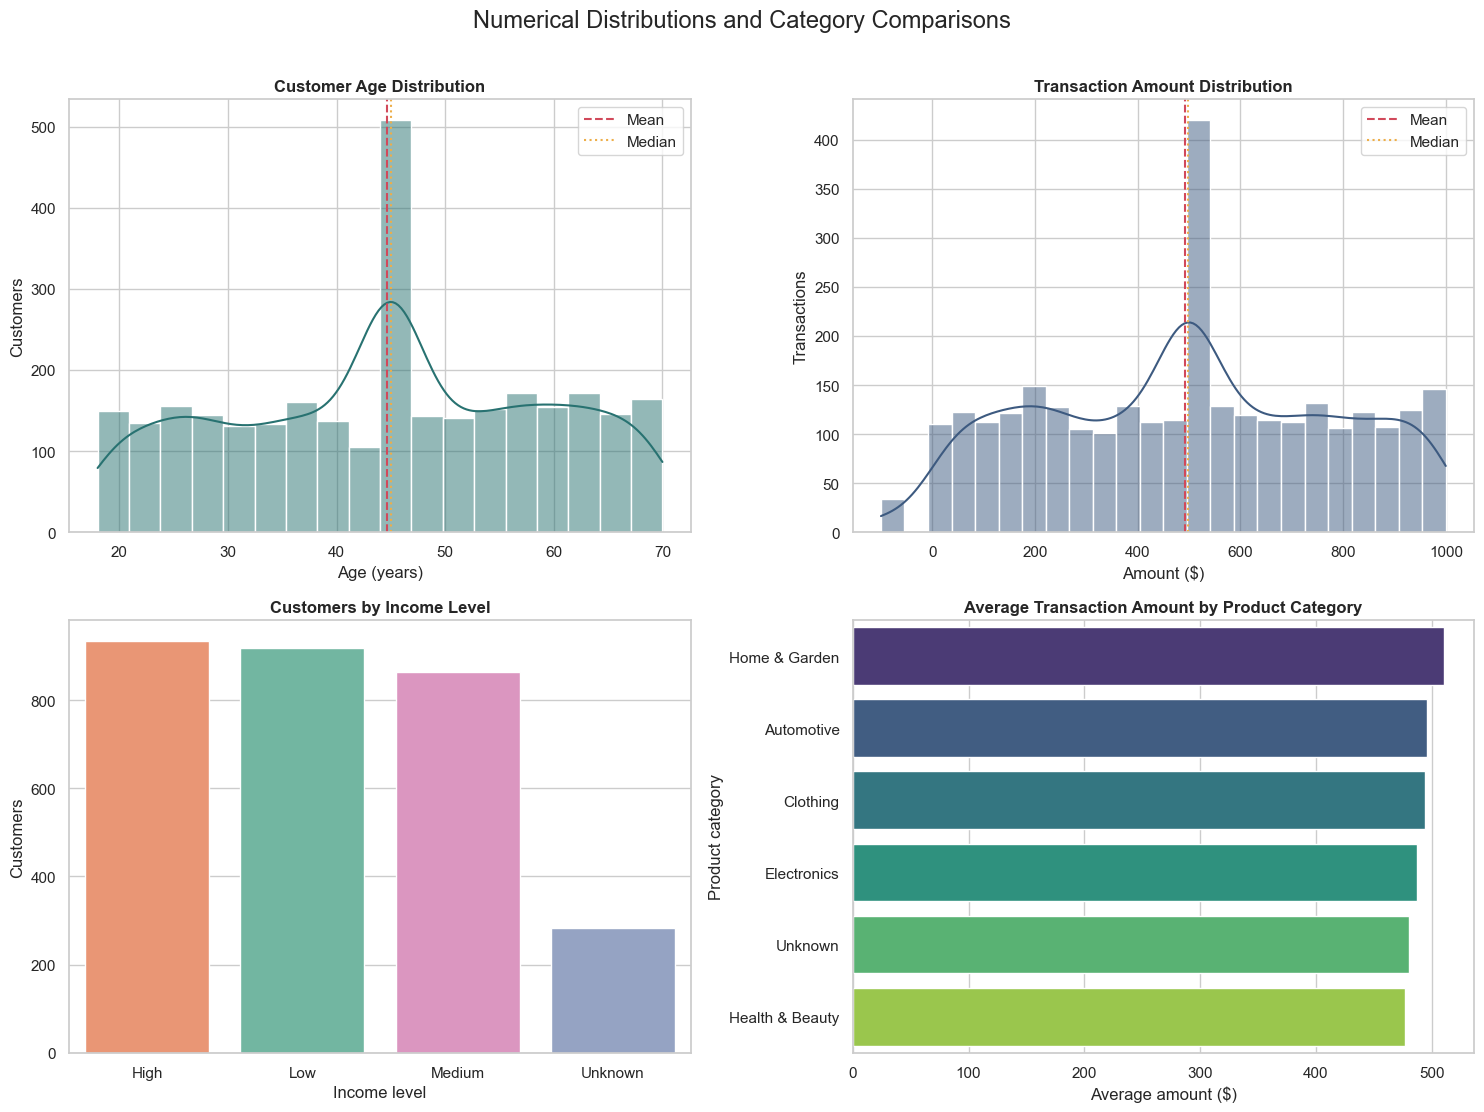

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.histplot(segments_eda, x="Age", bins=18, kde=True, color="#287271", ax=axes[0, 0])
axes[0, 0].axvline(segments_eda["Age"].mean(), color="#D1495B", linestyle="--", label="Mean")
axes[0, 0].axvline(segments_eda["Age"].median(), color="#EDAE49", linestyle=":", label="Median")
axes[0, 0].set(title="Customer Age Distribution", xlabel="Age (years)", ylabel="Customers")
axes[0, 0].legend()

sns.histplot(transactions_eda, x="Amount", bins=24, kde=True, color="#3D5A80", ax=axes[0, 1])
axes[0, 1].axvline(transactions_eda["Amount"].mean(), color="#D1495B", linestyle="--", label="Mean")
axes[0, 1].axvline(transactions_eda["Amount"].median(), color="#EDAE49", linestyle=":", label="Median")
axes[0, 1].set(title="Transaction Amount Distribution", xlabel="Amount ($)", ylabel="Transactions")
axes[0, 1].legend()

income_order = segments_eda["IncomeLevel"].value_counts().index
sns.countplot(data=segments_eda, x="IncomeLevel", order=income_order, hue="IncomeLevel", palette="Set2", legend=False, ax=axes[1, 0])
axes[1, 0].set(title="Customers by Income Level", xlabel="Income level", ylabel="Customers")

category_means = transactions_eda.groupby("ProductCategory", as_index=False)["Amount"].mean().sort_values("Amount", ascending=False)
sns.barplot(data=category_means, x="Amount", y="ProductCategory", hue="ProductCategory", palette="viridis", legend=False, ax=axes[1, 1])
axes[1, 1].set(title="Average Transaction Amount by Product Category", xlabel="Average amount ($)", ylabel="Product category")

fig.suptitle("Numerical Distributions and Category Comparisons", fontsize=17, y=1.01)
plt.tight_layout()
plt.show()

### Interpretation: Distributions and Categories
- **Age:** Mean and median remain close, indicating little overall skew. The spike at the median age is an imputation artifact and should be represented by a missingness indicator in later modeling.
- **Transaction amount:** Amount calculations use 2,971 records because the 29 `"Free"` labels remain unresolved. Median-imputed source-missing values can create a visible central spike; negative values remain signed pending confirmation that they are refunds or adjustments.
- **Income balance:** High, Low, and Medium income groups are similar in size. The `Unknown` group is smaller but meaningful and should remain distinguishable in future models.
- **Product comparison:** Category frequencies and average transaction amounts are relatively balanced. These averages are descriptive and remain conditional on the unresolved amount business rules.

## Relationships Between Variables
Transactions and social interactions are aggregated by `CustomerID` before merging with demographics. This avoids assuming that row positions across separate files refer to the same customer.

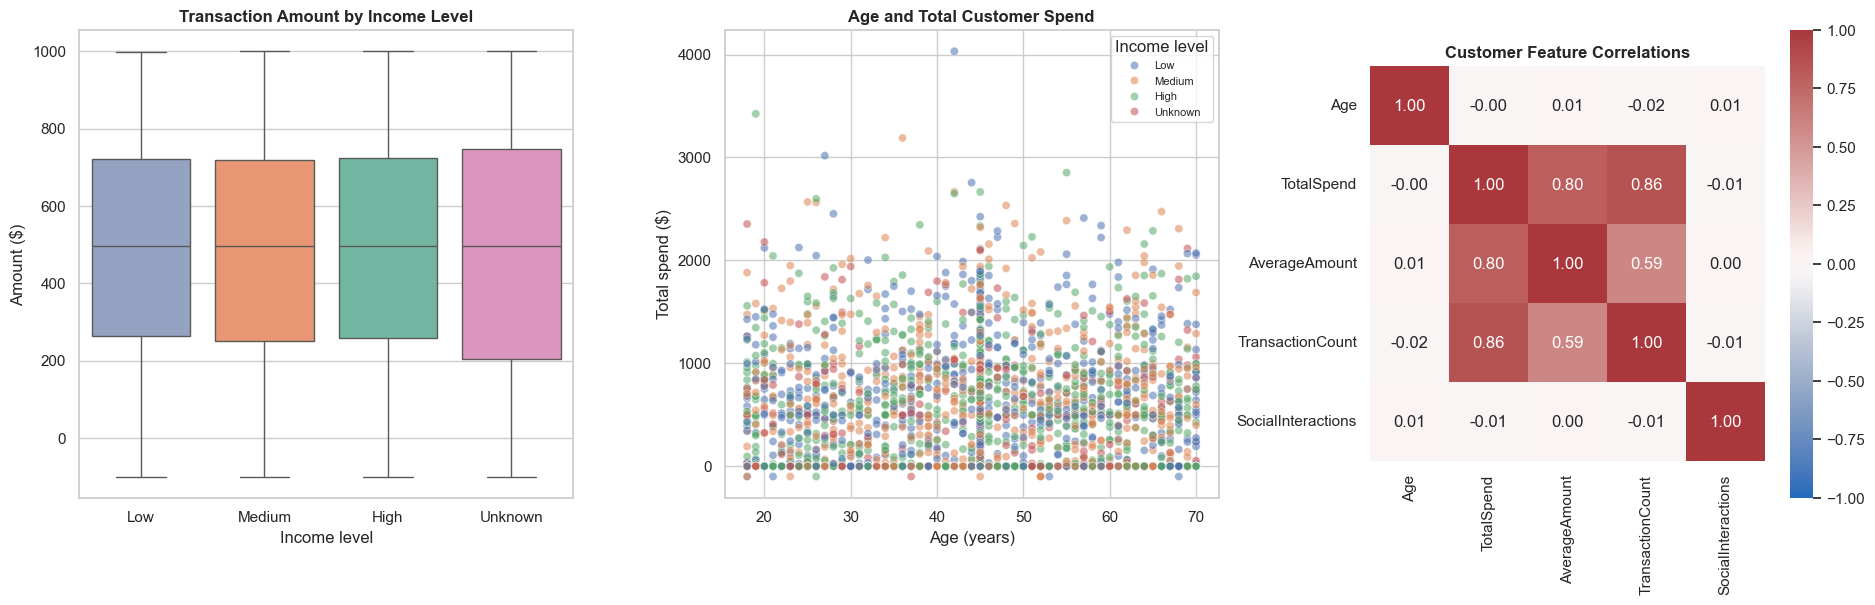

Matched transaction records: 3,000
Age-amount correlation after CustomerID join: 0.030


,count,mean,median
IncomeLevel,,,
High,940,492.59,497.49
Low,890,497.38,497.49
Medium,877,486.88,497.49
Unknown,264,487.97,497.49


In [23]:
transaction_features = transactions_eda.groupby("CustomerID").agg(
    TotalSpend=("Amount", "sum"),
    AverageAmount=("Amount", "mean"),
    TransactionCount=("TransactionID", "count"),
).reset_index()

social_features = social_eda.groupby("CustomerID").agg(
    SocialInteractions=("InteractionID", "count"),
).reset_index()

customer_features = (
    segments_eda[["CustomerID", "Age", "Gender", "IncomeLevel"]]
    .merge(transaction_features, on="CustomerID", how="left")
    .merge(social_features, on="CustomerID", how="left")
)
feature_columns = ["TotalSpend", "AverageAmount", "TransactionCount", "SocialInteractions"]
customer_features[feature_columns] = customer_features[feature_columns].fillna(0)

transaction_demographics = transactions_eda.merge(
    segments_eda[["CustomerID", "Age", "IncomeLevel"]],
    on="CustomerID",
    how="inner",
)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

income_order = ["Low", "Medium", "High", "Unknown"]
sns.boxplot(data=transaction_demographics, x="IncomeLevel", y="Amount", order=income_order, hue="IncomeLevel", palette="Set2", legend=False, ax=axes[0])
axes[0].set(title="Transaction Amount by Income Level", xlabel="Income level", ylabel="Amount ($)")

sns.scatterplot(data=customer_features, x="Age", y="TotalSpend", hue="IncomeLevel", hue_order=income_order, alpha=0.55, s=35, ax=axes[1])
axes[1].set(title="Age and Total Customer Spend", xlabel="Age (years)", ylabel="Total spend ($)")
axes[1].legend(title="Income level", fontsize=8)

correlation_columns = ["Age", "TotalSpend", "AverageAmount", "TransactionCount", "SocialInteractions"]
correlation_matrix = customer_features[correlation_columns].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=axes[2])
axes[2].set_title("Customer Feature Correlations")

plt.tight_layout()
plt.show()

print(f"Matched transaction records: {len(transaction_demographics):,}")
print(f"Age-amount correlation after CustomerID join: {transaction_demographics['Age'].corr(transaction_demographics['Amount']):.3f}")
display(transaction_demographics.groupby("IncomeLevel")["Amount"].agg(["count", "mean", "median"]).round(2))

### Interpretation: Relationships
- **Age and spending:** The joined correlation measures linear association only and does not establish that age causes spending differences.
- **Income and transaction amount:** Group means and medians are descriptive; differences should be tested formally before treating income level as a useful predictor.
- **Customer behavior features:** `TotalSpend`, `AverageAmount`, and `TransactionCount` are mathematically related, so including all three in a linear model may introduce multicollinearity.
- **Social activity:** Simple interaction volume should not be assumed to explain spending without richer timing, platform, and sentiment features.
- **Machine-learning relevance:** Engineered behavioral features are preferable to raw IDs. Categorical variables require encoding, `Unknown` must remain distinguishable, and amount-review flags should be retained until business validation is complete.

## Time Trends and Social Media Patterns
Monthly aggregation reveals whether transaction volume, average purchase size, and social activity show sustained trends or isolated peaks.

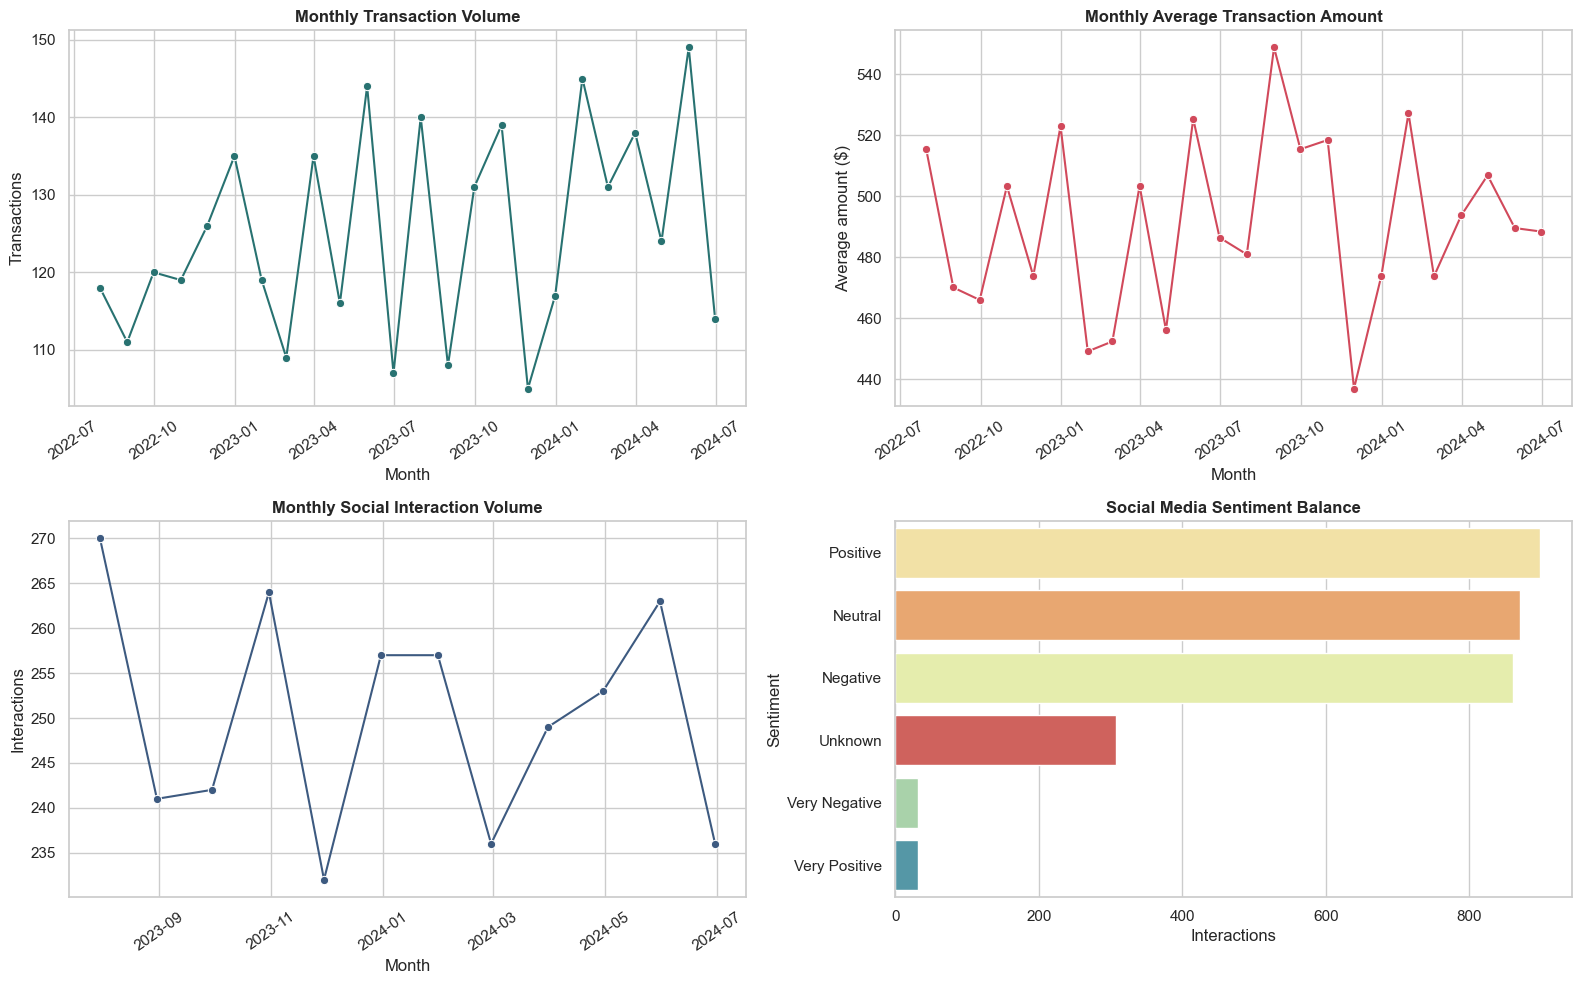

Peak transaction volume: May 2024 (149)
Highest monthly average amount: August 2023 ($548.84)
Peak social activity: July 2023 (270)


In [24]:
monthly_transactions = (
    transactions_eda.set_index("TransactionDate")
    .resample("ME")
    .agg(TransactionCount=("TransactionID", "count"), AverageAmount=("Amount", "mean"))
)
monthly_social = (
    social_eda.set_index("InteractionDate")
    .resample("ME")
    .agg(InteractionCount=("InteractionID", "count"))
)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.lineplot(data=monthly_transactions, x=monthly_transactions.index, y="TransactionCount", marker="o", color="#287271", ax=axes[0, 0])
axes[0, 0].set(title="Monthly Transaction Volume", xlabel="Month", ylabel="Transactions")

sns.lineplot(data=monthly_transactions, x=monthly_transactions.index, y="AverageAmount", marker="o", color="#D1495B", ax=axes[0, 1])
axes[0, 1].set(title="Monthly Average Transaction Amount", xlabel="Month", ylabel="Average amount ($)")

sns.lineplot(data=monthly_social, x=monthly_social.index, y="InteractionCount", marker="o", color="#3D5A80", ax=axes[1, 0])
axes[1, 0].set(title="Monthly Social Interaction Volume", xlabel="Month", ylabel="Interactions")

sentiment_order = social_eda["Sentiment"].value_counts().index
sns.countplot(data=social_eda, y="Sentiment", order=sentiment_order, hue="Sentiment", palette="Spectral", legend=False, ax=axes[1, 1])
axes[1, 1].set(title="Social Media Sentiment Balance", xlabel="Interactions", ylabel="Sentiment")

for axis in axes.flat[:3]:
    axis.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

peak_volume_month = monthly_transactions["TransactionCount"].idxmax()
peak_average_month = monthly_transactions["AverageAmount"].idxmax()
peak_social_month = monthly_social["InteractionCount"].idxmax()
print(f"Peak transaction volume: {peak_volume_month:%B %Y} ({monthly_transactions.loc[peak_volume_month, 'TransactionCount']:.0f})")
print(f"Highest monthly average amount: {peak_average_month:%B %Y} (${monthly_transactions.loc[peak_average_month, 'AverageAmount']:,.2f})")
print(f"Peak social activity: {peak_social_month:%B %Y} ({monthly_social.loc[peak_social_month, 'InteractionCount']:.0f})")

### Interpretation: Trends and Imbalances
- **Transaction volume:** Monthly counts fluctuate, but two years of data are insufficient to establish seasonality.
- **Purchase value:** Monthly averages describe the available numeric amounts; they exclude unresolved `"Free"` labels and include signed negative amounts pending business confirmation.
- **Sentiment:** Positive, Neutral, and Negative interactions are much more common than the extreme sentiment classes, which may create class imbalance if detailed sentiment becomes a prediction target.
- **Data quality and modeling:** The `Unknown` sentiment class should not be silently merged with Neutral. Classification may require stratified splitting, class weights, or carefully justified category consolidation.

## Outliers and Unusual Observations
Box plots and the 1.5 × IQR rule provide a consistent way to flag potential outliers without assuming a normal distribution.

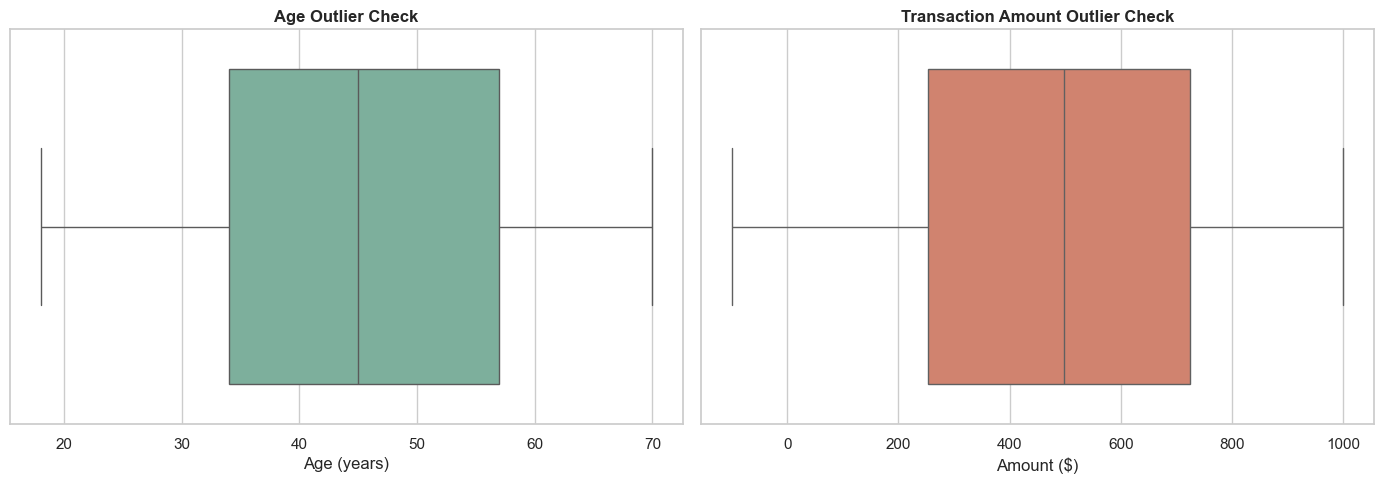

,Valid observations,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
Customer Age,3000.0,34.00,57.00,23.00,-0.50,91.50,0.0
Transaction Amount,2971.0,253.25,724.22,470.98,-453.21,1430.69,0.0


Genuine numeric zero amounts: 29
Unresolved Free labels: 29
Signed negative amounts: 34
Median-imputed source-missing amounts: 282


In [25]:
def iqr_outlier_summary(series):
    series = pd.Series(series).dropna()
    q1, q3 = np.percentile(series, [25, 75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((series < lower_bound) | (series > upper_bound)).sum()
    return {
        "Valid observations": len(series),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers": int(outlier_count),
    }

outlier_summary = pd.DataFrame({
    "Customer Age": iqr_outlier_summary(segments_eda["Age"]),
    "Transaction Amount": iqr_outlier_summary(transactions_eda["Amount"]),
}).T

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=segments_eda["Age"], color="#75B79E", ax=axes[0])
axes[0].set(title="Age Outlier Check", xlabel="Age (years)")
sns.boxplot(x=transactions_eda["Amount"], color="#E07A5F", ax=axes[1])
axes[1].set(title="Transaction Amount Outlier Check", xlabel="Amount ($)")
plt.tight_layout()
plt.show()

display(outlier_summary.round(2))
print(f"Genuine numeric zero amounts: {(transactions_eda['Amount'] == 0).sum():,}")
print(f"Unresolved Free labels: {transactions_eda['IsFreeLabel'].sum():,}")
print(f"Signed negative amounts: {transactions_eda['IsNegativeAmount'].sum():,}")
print(f"Median-imputed source-missing amounts: {transactions_eda['WasAmountImputed'].sum():,}")

### Interpretation: Outliers and Next Steps
- IQR flags identify unusual observations, not automatic errors. Signed negative amounts are reviewed separately because their possible refund/reversal meaning is a business-semantic question rather than a purely statistical outlier question.
- Genuine numeric zeros, unresolved `"Free"` labels, signed negatives, and median-imputed amounts are counted separately. This prevents distinct transaction states from being collapsed into one value.
- Broad transaction variability may be genuine distribution spread. Scaling can help some model families, but records should not be removed solely for being near a statistical threshold.
- Before modeling, FinMark should confirm whether negative amounts belong in net-spend features and whether `"Free"` means zero consideration, a promotion, or missing data. The audit flags should remain available for sensitivity analysis.
- Time-based prediction should use chronological train/test splits to avoid leakage. Customer-level prediction should split by `CustomerID` so records from the same customer do not appear in both training and testing data.